### Loading and Preparing the Daily Minimum Temperatures Dataset

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# URL to the raw dataset on GitHub
url = 'https://raw.githubusercontent.com/jbrownlee/Datasets/master/daily-min-temperatures.csv'
temp_data = pd.read_csv(url)

# Convert Date column to datetime and sort
temp_data['Date'] = pd.to_datetime(temp_data['Date'])
temp_data = temp_data.sort_values('Date')
temp_data = temp_data.drop_duplicates(subset='Date', keep='last')
temp_data = temp_data.set_index('Date')

# Convert Temp column to numeric and drop NaN values
temp_data['Temp'] = pd.to_numeric(temp_data['Temp'], errors='coerce')
temp_data = temp_data.dropna(subset=['Temp'])

# Resample data to find the yearly mean temperature
resampled_temp = temp_data['Temp'].resample('YE').mean().to_frame()
resampled_temp.index = resampled_temp.index.year
resampled_temp.index.name = 'Year'
resampled_temp = resampled_temp.reset_index()

display(resampled_temp.head())


,Year,Temp
0,1981,11.517260
1,1982,10.783562
2,1983,11.187397
3,1984,10.591781
4,1985,11.137534


### Trend Estimation for Yearly Mean Temperatures

In [ ]:
years = resampled_temp['Year'].tolist()
temps = resampled_temp['Temp'].tolist()

# Set X relative to the middle year to avoid numerical instability
X = [i - years[len(years) // 2] for i in years]
x2 = [i ** 2 for i in X]
xy = [i * j for i, j in zip(X, temps)]

n = len(years)

# Calculate linear trend coefficients (y = a + bx)
b = (n * sum(xy) - sum(temps) * sum(X)) / (n * sum(x2) - sum(X) ** 2)
a = (sum(temps) - b * sum(X)) / n
linear_trend = [a + b * X[i] for i in range(n)]

# Calculate polynomial trend coefficients (y = a + bx + cx^2)
x3 = [i ** 3 for i in X]
x4 = [i ** 4 for i in X]
temp_x2 = [i * j for i, j in zip(x2, temps)]

coeff = [
    [n, sum(X), sum(x2)],
    [sum(X), sum(x2), sum(x3)],
    [sum(x2), sum(x3), sum(x4)]
]

Y = [sum(temps), sum(xy), sum(temp_x2)]

A = np.array(coeff, dtype=float)
B = np.array(Y, dtype=float)

solution = np.linalg.solve(A, B)
a_poly, b_poly, c_poly = solution
poly_trend = [a_poly + b_poly * X[i] + c_poly * X[i] ** 2 for i in range(n)]

resampled_temp['Linear Trend'] = linear_trend
resampled_temp['Polynomial Trend'] = poly_trend
resampled_temp.set_index('Year', inplace=True)


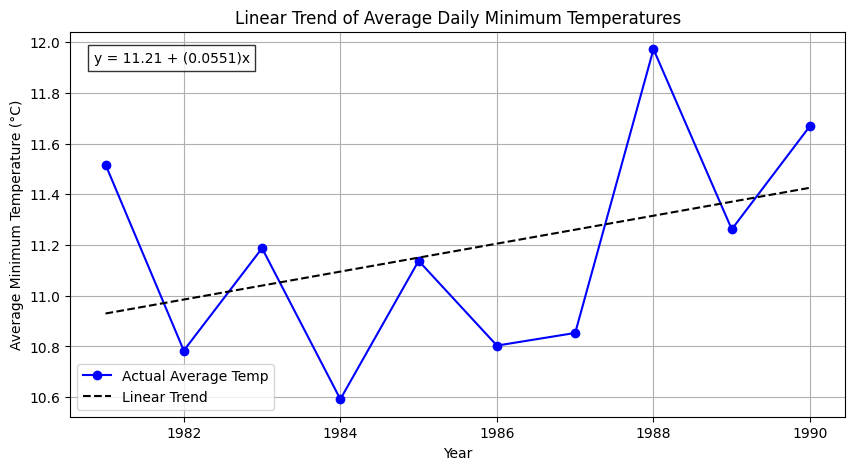

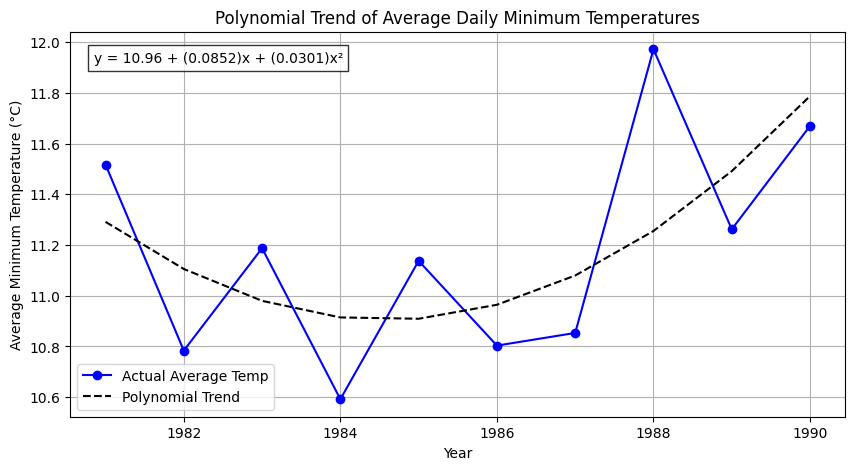

In [ ]:
# Plot Linear Trend
plt.figure(figsize=(10, 5))
resampled_temp['Temp'].plot(kind='line', color='blue', marker='o', label='Actual Average Temp')
resampled_temp['Linear Trend'].plot(kind='line', color='black', linestyle='--', label='Linear Trend')
plt.text(
    0.03, 0.95,
    f'y = {a:.2f} + ({b:.4f})x',
    transform=plt.gca().transAxes,
    verticalalignment='top',
    bbox=dict(facecolor='white', alpha=0.8)
)
plt.title('Linear Trend of Average Daily Minimum Temperatures')
plt.xlabel('Year')
plt.ylabel('Average Minimum Temperature (°C)')
plt.legend()
plt.grid(True)
plt.show()

# Plot Polynomial Trend
plt.figure(figsize=(10, 5))
resampled_temp['Temp'].plot(kind='line', color='blue', marker='o', label='Actual Average Temp')
resampled_temp['Polynomial Trend'].plot(kind='line', color='black', linestyle='--', label='Polynomial Trend')
plt.text(
    0.03, 0.95,
    f'y = {a_poly:.2f} + ({b_poly:.4f})x + ({c_poly:.4f})x²',
    transform=plt.gca().transAxes,
    verticalalignment='top',
    bbox=dict(facecolor='white', alpha=0.8)
)
plt.title('Polynomial Trend of Average Daily Minimum Temperatures')
plt.xlabel('Year')
plt.ylabel('Average Minimum Temperature (°C)')
plt.legend()
plt.grid(True)
plt.show()
